# Physics 4A: Constitutive Law P11

In [1]:
from constitutive_laws_generator import LinearElasticConstitutiveLaw, NeoHookeanConstitutiveLaw
import copy
import dataclasses
import torch
import matplotlib.pyplot as plt
import numpy as np
import random
from sympy import expand, symbols
from xkan import KANNetwork, fit, create_dataset_from_data
from xkan.symbolic import compile_formula
from xkan.viz import plot

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.use_deterministic_algorithms(True)
torch.set_default_dtype(torch.float64)

N = 1000
sigma = 0.2

F = torch.eye(3,3)[None,:,:].expand(N,3,3) + (torch.rand(N,3,3)*2-1)*sigma
det = torch.det(F)
F *= (det > 0)[:,None,None]

linear = LinearElasticConstitutiveLaw(young_modulus=1.0, poisson_ratio=0.2)
P_l = linear(F)
P11_l = P_l[:,[0],[0]]
P12_l = P_l[:,[0],[1]]

neo = NeoHookeanConstitutiveLaw(young_modulus=1.0, poisson_ratio=0.2)
P_n = neo(F)
P11_n = P_n[:,[0],[0]]
P12_n = P_n[:,[0],[1]]

# P11
# linear: P11 = 2 * mu * (F11 - 1) + lambda * (F11 + F22 + F33 - 3)
# neohookean: P11 = mu * (F11^2 + F12^2 + F13^2 - 1) + lambda * log(|F|)

# P12
# linear: P12 = mu * (F12 + F21)
# neohookean: P12 = mu * (F11 * F21 + F12 * F22 + F13 * F23)

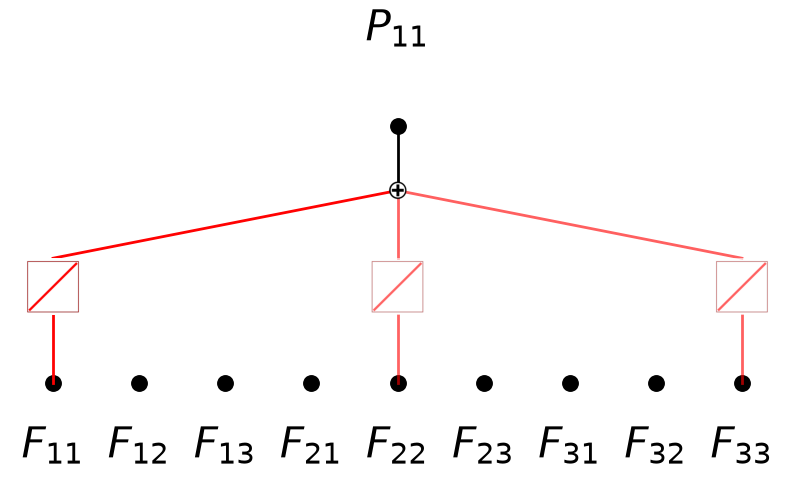

In [2]:
mu, lambda_ = linear.get_lame_parameters()
input_vars = F11, F12, F13, F21, F22, F23, F31, F32, F33 = symbols('F11 F12 F13 F21 F22 F23 F31 F32 F33')
P11_l_expr = 2 * mu * (F11 - 1) + lambda_ * (F11 + F22 + F33 - 3)
# seed=4: the starting point of the network (its initial curves); run from top to bottom, most seeds recover the law
# below exactly, the default seed (1) leaves a small extra term
model = compile_formula(input_vars, P11_l_expr, seed=4)

F_flatten = F.reshape(N, -1)

plot(model, F_flatten, in_vars=input_vars, out_vars=[r'$P_{11}$'], varscale=0.75, scale=1.0);

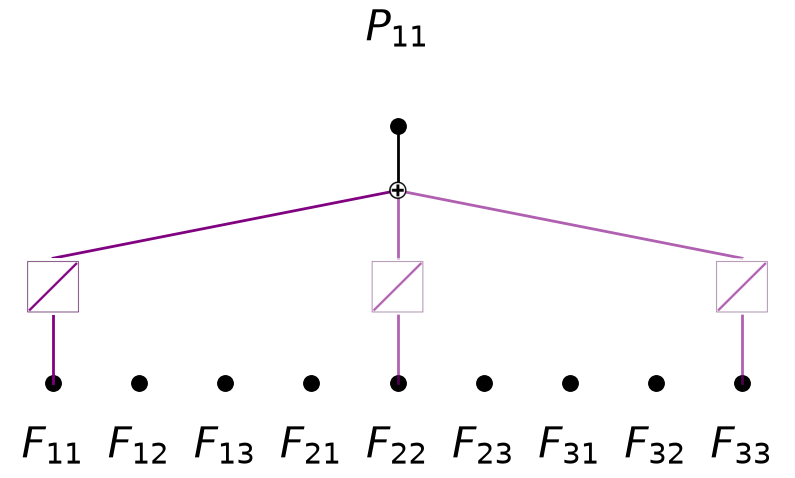

In [3]:
from xkan.interp import perturb
perturb(model)
plot(model, F_flatten, in_vars=input_vars, out_vars=[r'$P_{11}$'], varscale=0.75, scale=1.0);

In [4]:
train, test = create_dataset_from_data(F_flatten, P11_n)
history = fit(model, train, test, steps=20)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.006407340691359777 test RMSE 0.007009947843441463


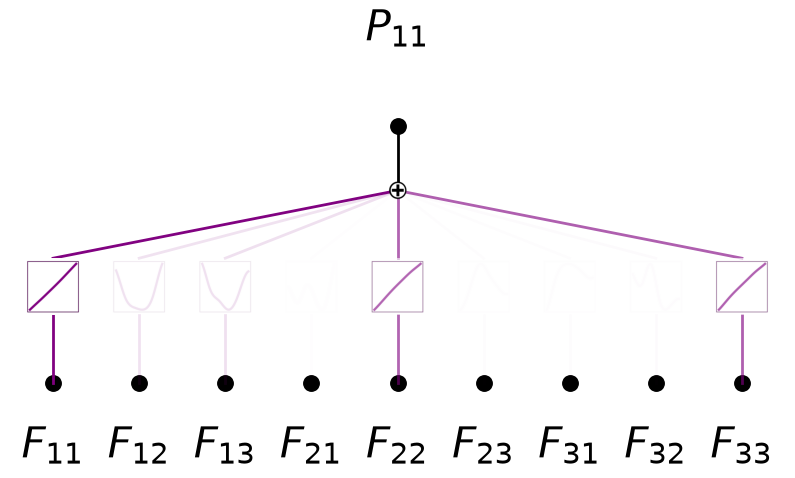

In [5]:
plot(model, train['x'], in_vars=input_vars, out_vars=[r'$P_{11}$'], varscale=0.75, scale=1.0);

In [6]:
from xkan.utils import augment_input
detF = F11 * F22 * F33 + F12 * F23 * F31 + F13 * F21 * F32 - F11 * F23 * F32 - F12 * F21 * F33 - F13 * F22 * F31
D = symbols('|F|')

# |F| as a new first input column of the training and test inputs
train['x'] = augment_input(input_vars, [detF], train['x'])
test['x'] = augment_input(input_vars, [detF], test['x'])

In [7]:
def expand_inputs(model, n_added):
    """
    a network with n_added new inputs before the old ones, their numeric edges switched on with the curves of a new
    network; every old curve, symbolic edge and affine parameter kept (expand_width adds hidden nodes only)
    """
    cfg = model.config
    new = KANNetwork.from_config(dataclasses.replace(cfg, width=((cfg.width[0][0] + n_added, 0),) + cfg.width[1:]),
                                 device=model.device, dtype=model.dtype)
    in_map, out_map = [None] * n_added + list(range(model.width_in[0])), list(range(model.width_out[1]))
    layer = model.layers[0].reindexed(in_map, out_map)
    with torch.no_grad():
        for name in ('grid', 'coef', 'scale_base', 'scale_sp', 'mask'):
            getattr(layer, name)[:n_added] = getattr(new.layers[0], name)[:n_added]
    new.layers[0] = layer
    new.symbolic[0] = model.symbolic[0].reindexed(in_map, out_map)
    for l in range(1, model.depth):
        new.layers[l], new.symbolic[l] = copy.deepcopy(model.layers[l]), copy.deepcopy(model.symbolic[l])
    with torch.no_grad():
        for name in ('subnode_scale', 'subnode_bias', 'node_scale', 'node_bias'):
            for a, b in zip(getattr(new, name), getattr(model, name)):
                a.copy_(b)
    return new

model = expand_inputs(model, 1)

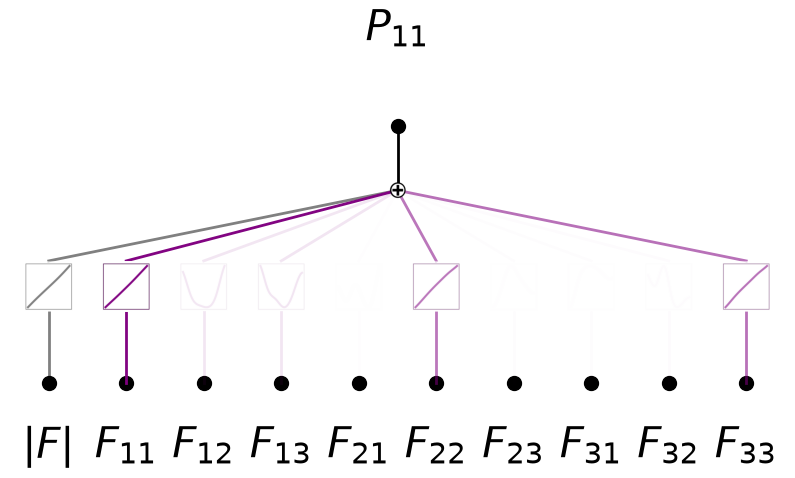

In [8]:
plot(model, train['x'], in_vars=[D] + list(input_vars), out_vars=[r'$P_{11}$'], varscale=0.75, scale=1.0);

In [9]:
history = fit(model, train, test, opt='lbfgs', steps=20)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.00040692803010105 test RMSE 0.0003469709108910902


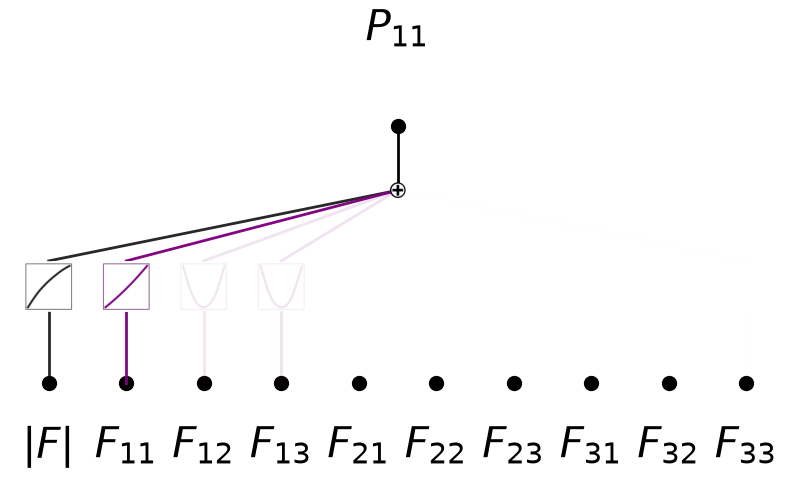

In [10]:
plot(model, train['x'], in_vars=[D] + list(input_vars), out_vars=[r'$P_{11}$'], varscale=0.75, scale=1.0);

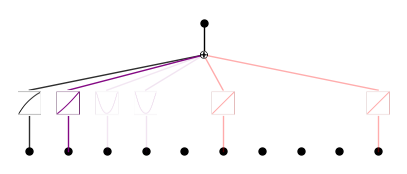

In [11]:
from xkan.interp import prune
model = prune(model, train['x'])
plot(model, train['x']);

In [12]:
from xkan.symbolic import auto_symbolic
auto_symbolic(model, train['x'])

skipping (0,4,0) since already symbolic
skipping (0,5,0) since already symbolic
skipping (0,6,0) since already symbolic
skipping (0,7,0) since already symbolic
skipping (0,8,0) since already symbolic
skipping (0,9,0) since already symbolic


fixing (0,0,0) with log, r2=0.9999648827754543, c=2


fixing (0,1,0) with x^2, r2=0.9999995629955726, c=2


fixing (0,2,0) with x^2, r2=0.9996487521862558, c=2


fixing (0,3,0) with x^2, r2=0.998833444327692, c=2


{(0, 0, 0): ('log', np.float64(0.9999648827754543), np.int64(2)),
 (0, 1, 0): ('x^2', np.float64(0.9999995629955726), np.int64(2)),
 (0, 2, 0): ('x^2', np.float64(0.9996487521862558), np.int64(2)),
 (0, 3, 0): ('x^2', np.float64(0.998833444327692), np.int64(2))}

In [13]:
history = fit(model, train, test, opt='lbfgs', steps=100)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 1.1375692371706448e-06 test RMSE 1.1188021171387848e-06


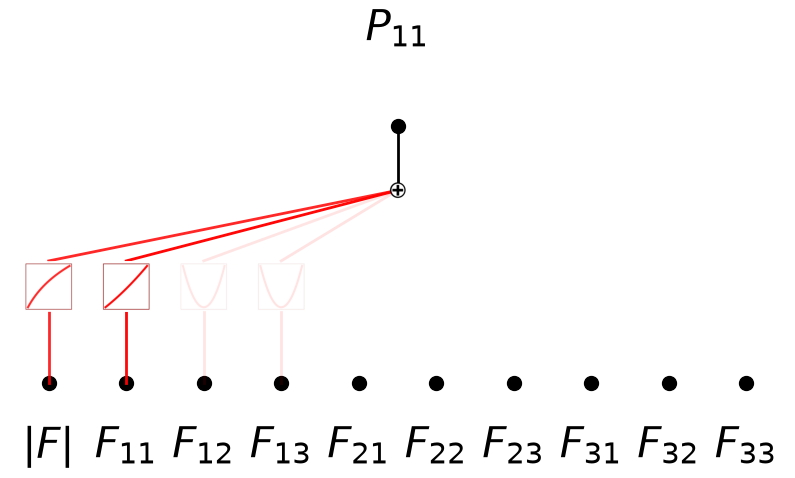

In [14]:
plot(model, train['x'], in_vars=[D] + list(input_vars), out_vars=[r'$P_{11}$'], varscale=0.75, scale=1.0);

In [15]:
from xkan.symbolic import symbolic_formula
from xkan.utils import ex_round

# expanded before rounding: rounding first can drop a term (a small factor in front of a large inner one)
ex_round(expand(symbolic_formula(model, var=[D] + list(input_vars))[0][0]), 2)

0.42*F11**2 + 0.42*F12**2 + 0.42*F13**2 + 0.28*log(3.8*|F|) - 0.79

In [16]:
0.28*np.log(2.5) - 0.67

np.float64(-0.41343859507523656)